# Machine Learning Laboratory
## Experiment 07: Decision Tree Classification using ID3

### Aim
To implement a Decision Tree classification algorithm using the ID3 approach and Information Gain, and use the resulting tree to classify new observations.

### Step 1: Import Libraries
Here, pandas is used to manipulate the dataset and math is used for logarithmic calculations.

In [1]:
import pandas as pd
import math

### Step 2: Create the Dataset

In [2]:
data = {
    "Outlook": [
        "Sunny", "Sunny", "Overcast", "Rain",
        "Rain", "Rain", "Overcast", "Sunny",
        "Sunny", "Rain", "Sunny", "Overcast",
        "Overcast", "Rain"
    ],
    "Temperature": [
        "Hot", "Hot", "Hot", "Mild",
        "Cool", "Cool", "Cool", "Mild",
        "Cool", "Mild", "Mild", "Mild",
        "Hot", "Mild"
    ],
    "Humidity": [
        "High", "High", "High", "High",
        "Normal", "Normal", "Normal", "High",
        "Normal", "Normal", "Normal", "High",
        "Normal", "High"
    ],
    "Wind": [
        "Weak", "Strong", "Weak", "Weak",
        "Weak", "Strong", "Strong", "Weak",
        "Weak", "Weak", "Strong", "Strong",
        "Weak", "Strong"
    ],
    "Play": [
        "No", "No", "Yes", "Yes",
        "Yes", "No", "Yes", "No",
        "Yes", "Yes", "Yes", "Yes",
        "Yes", "No"
    ]
}

df = pd.DataFrame(data)
print(df)

     Outlook Temperature Humidity    Wind Play
0      Sunny         Hot     High    Weak   No
1      Sunny         Hot     High  Strong   No
2   Overcast         Hot     High    Weak  Yes
3       Rain        Mild     High    Weak  Yes
4       Rain        Cool   Normal    Weak  Yes
5       Rain        Cool   Normal  Strong   No
6   Overcast        Cool   Normal  Strong  Yes
7      Sunny        Mild     High    Weak   No
8      Sunny        Cool   Normal    Weak  Yes
9       Rain        Mild   Normal    Weak  Yes
10     Sunny        Mild   Normal  Strong  Yes
11  Overcast        Mild     High  Strong  Yes
12  Overcast         Hot   Normal    Weak  Yes
13      Rain        Mild     High  Strong   No


### Step 3: Calculate Entropy
The entropy function calculates the impurity of the target variable.

In [3]:
def entropy(target):
    values = target.value_counts()
    total = len(target)
    entropy_value = 0
    for count in values:
        probability = count / total
        entropy_value -= probability * math.log2(probability)
    return entropy_value

print("Entropy of dataset:",
      entropy(df["Play"]))

Entropy of dataset: 0.9402859586706311


### Step 4: Calculate Information Gain
Information Gain is calculated for each attribute.

In [4]:
def information_gain(data, attribute, target_name):
    total_entropy = entropy(data[target_name])
    values = data[attribute].unique()
    weighted_entropy = 0
    for value in values:
        subset = data[data[attribute] == value]
        probability = len(subset) / len(data)
        weighted_entropy += (
            probability *
            entropy(subset[target_name])
        )
    gain = total_entropy - weighted_entropy
    return gain

### Step 5: Calculate Information Gain for All Attributes

In [5]:
attributes = [
    "Outlook",
    "Temperature",
    "Humidity",
    "Wind"
]
for attribute in attributes:
    gain = information_gain(
        df,
        attribute,
        "Play"
    )
    print(attribute, ":", gain)

Outlook : 0.24674981977443933
Temperature : 0.02922256565895487
Humidity : 0.15183550136234159
Wind : 0.04812703040826949


### Step 6: Find the Best Attribute
Instead of manually selecting the attribute, create a function that automatically selects the attribute with maximum Information Gain.

In [6]:
def best_attribute(data, attributes, target_name):
    best_gain = -1
    best_attr = None
    for attribute in attributes:
        gain = information_gain(
            data,
            attribute,
            target_name
        )
        if gain > best_gain:
            best_gain = gain
            best_attr = attribute
    return best_attr

attributes = [
    "Outlook",
    "Temperature",
    "Humidity",
    "Wind"
]
print(
    "Best attribute:",
    best_attribute(df, attributes, "Play")
)

Best attribute: Outlook


### Step 7: Implement the ID3 Algorithm Recursively
The following function implements the main ID3 algorithm.

In [7]:
def id3(data, attributes, target_name):
    # Case 1: All samples belong to one class
    if len(data[target_name].unique()) == 1:
        return data[target_name].iloc[0]
    # Case 2: No attributes remain
    if len(attributes) == 0:
        return data[target_name].mode()[0]
    # Select the best attribute
    best_attr = best_attribute(
        data,
        attributes,
        target_name
    )
    tree = {best_attr: {}}
    # Create a branch for every value
    for value in data[best_attr].unique():
        subset = data[
            data[best_attr] == value
        ]
        remaining_attributes = [
            attr for attr in attributes
            if attr != best_attr
        ]
        tree[best_attr][value] = id3(
            subset,
            remaining_attributes,
            target_name
        )
    return tree

### Step 8: Build the Decision Tree

In [8]:
attributes = [
    "Outlook",
    "Temperature",
    "Humidity",
    "Wind"
]
tree = id3(
    df,
    attributes,
    "Play"
)
print(tree)

{'Outlook': {'Sunny': {'Humidity': {'High': 'No', 'Normal': 'Yes'}}, 'Overcast': 'Yes', 'Rain': {'Wind': {'Weak': 'Yes', 'Strong': 'No'}}}}


### Step 9: Prediction Function

In [9]:
def predict(tree, sample):
    if not isinstance(tree, dict):
        return tree
    attribute = list(tree.keys())[0]
    value = sample[attribute]
    subtree = tree[attribute][value]
    return predict(subtree, sample)

### Step 10: Predict a New Sample

In [10]:
new_sample = {
    "Outlook": "Sunny",
    "Temperature": "Cool",
    "Humidity": "High",
    "Wind": "Strong"
}
prediction = predict(tree, new_sample)
print("Prediction:", prediction)

Prediction: No


### 6. Testing the Model on the Dataset
Students can also use the constructed tree to generate predictions for the existing observations.

In [11]:
predictions = []
for index, row in df.iterrows():
    sample = row.drop("Play").to_dict()
    prediction = predict(tree, sample)
    predictions.append(prediction)

df["Predicted"] = predictions
print(df)

     Outlook Temperature Humidity    Wind Play Predicted
0      Sunny         Hot     High    Weak   No        No
1      Sunny         Hot     High  Strong   No        No
2   Overcast         Hot     High    Weak  Yes       Yes
3       Rain        Mild     High    Weak  Yes       Yes
4       Rain        Cool   Normal    Weak  Yes       Yes
5       Rain        Cool   Normal  Strong   No        No
6   Overcast        Cool   Normal  Strong  Yes       Yes
7      Sunny        Mild     High    Weak   No        No
8      Sunny        Cool   Normal    Weak  Yes       Yes
9       Rain        Mild   Normal    Weak  Yes       Yes
10     Sunny        Mild   Normal  Strong  Yes       Yes
11  Overcast        Mild     High  Strong  Yes       Yes
12  Overcast         Hot   Normal    Weak  Yes       Yes
13      Rain        Mild     High  Strong   No        No


### Accuracy
Calculate the number of correctly classified observations.

In [12]:
correct = sum(
    df["Play"] == df["Predicted"]
)
accuracy = correct / len(df)
print("Accuracy:", accuracy)

Accuracy: 1.0


### 7. Verify using Scikit-learn
After implementing ID3 manually, students can verify the concept using Scikit-learn.

In [13]:
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

df_encoded = df.drop("Predicted", axis=1).copy()
encoders = {}
for column in df_encoded.columns:
    encoder = LabelEncoder()
    df_encoded[column] = encoder.fit_transform(
        df_encoded[column]
    )
    encoders[column] = encoder

X = df_encoded.drop("Play", axis=1)
y = df_encoded["Play"]

model = DecisionTreeClassifier(
    criterion="entropy",
    random_state=42
)
model.fit(X, y)

y_pred = model.predict(X)
accuracy = accuracy_score(y, y_pred)
print("Accuracy:", accuracy)

Accuracy: 1.0


### 8. Visualization using Scikit-learn
The learned tree can also be visualized.

<ipython-input-1-9a72ecfbe812>:11: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


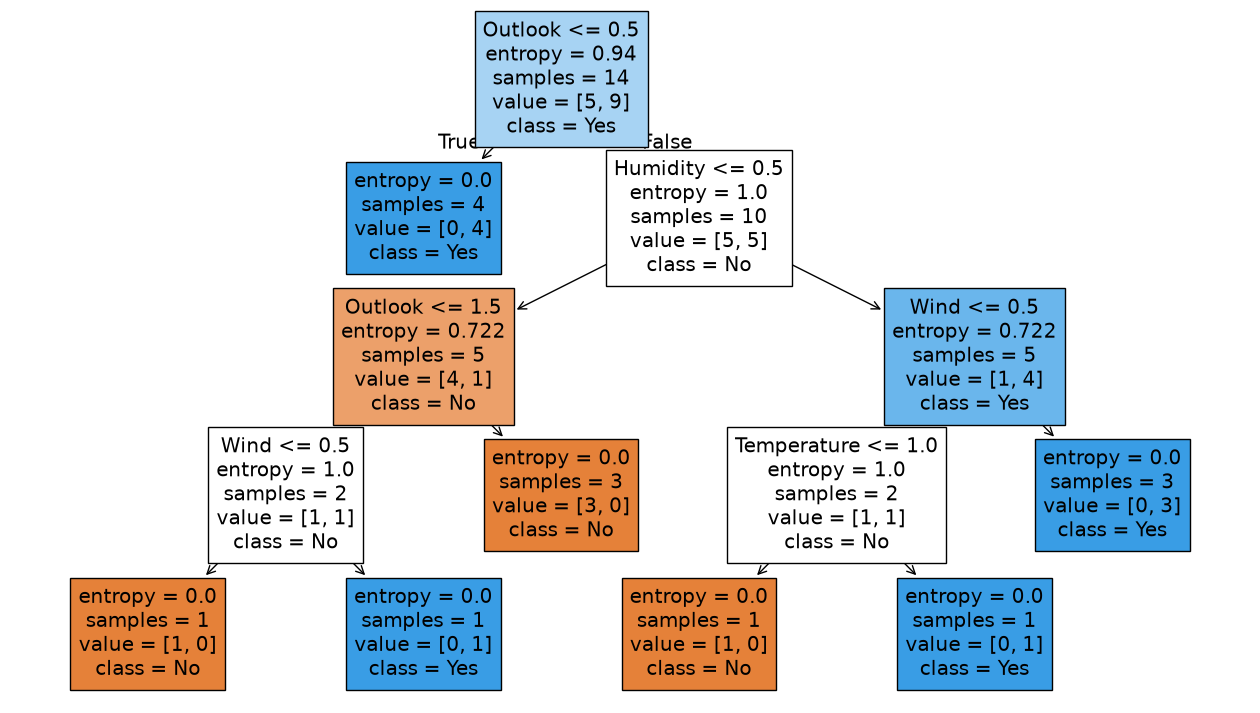

In [14]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(16, 9))
plot_tree(
    model,
    feature_names=X.columns,
    class_names=["No", "Yes"],
    filled=True
)
plt.show()